# Laptop Price Analysis
**2323 CIS | Introduction to Data Science — King Khalid University**

**Group 3:** Lena Ali Alsweed · Lamees Mansor · GHADAY Saeed · Lara Saleh · Samar saeed

**Research question:** How do laptop prices differ across brands and RAM sizes?

The original data are listed in euros. For a comparison that is easier to read in Saudi Arabia, the analysis also shows their converted values in Saudi riyals (SAR).

### Step 1 — Project Topic Selection
The project examines **Laptop Prices** because the price and technical specifications of laptops can be compared through tables and charts.


### Step 2 — Data Question and Project Objective
**Main question:** How do listed laptop prices differ across manufacturers and RAM sizes?

The objectives are to describe the price range, compare typical prices among brands, and examine differences across RAM groups. The analysis is descriptive rather than predictive.


### Step 3 — Download a Real Dataset from the Internet
**Data source:** Public [laptop_price.csv dataset](https://github.com/MainakRepositor/Datasets/blob/master/laptop_price.csv), accessed 24 November 2026. The dataset contains 1,303 laptop listings and 13 columns.

The source records prices in euros (`Price_euros`). A separate column (`Price_SAR`) represents the converted prices in Saudi riyals; the original values remain unchanged. The original data collection date is unspecified, and the converted values are not current prices in Saudi stores.

**Currency reference:** [X-Rates historical SAR rates, 23 November 2026](https://www.x-rates.com/historical/?amount=1&date=2026-11-23&from=SAR) — 1 EUR ≈ 4.1256 SAR. A fixed reference rate makes the conversion reproducible.


### Step 4 — Set Up the Working Environment
The analysis uses Python with pandas, NumPy, Matplotlib, and the `re` module for text patterns. The notebook is compatible with Google Colab and Jupyter Notebook.


In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# If opened from the notebooks/ folder, save outputs in the project folder.
project_folder = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
data_folder = project_folder / 'data'
figure_folder = project_folder / 'outputs' / 'figures'
data_folder.mkdir(parents=True, exist_ok=True)
figure_folder.mkdir(parents=True, exist_ok=True)
print('pandas version:', pd.__version__)

pandas version: 2.2.3


### Step 5 — Load the Dataset Using Python
The original CSV is loaded with pandas. If UTF-8 decoding fails, an alternative character encoding is used. An existing local copy is used when available.


In [2]:
# Data source
csv_url = 'https://raw.githubusercontent.com/MainakRepositor/Datasets/master/laptop_price.csv'
raw_file = data_folder / 'laptop_price.csv'

if raw_file.exists():
    source = raw_file
    print('Reading local file')
else:
    source = csv_url
    print('Reading the dataset from GitHub')

for encoding in ['utf-8-sig', 'cp1252', 'latin1']:
    try:
        raw = pd.read_csv(source, encoding=encoding)
        print('Encoding used:', encoding)
        break
    except UnicodeDecodeError:
        continue
else:
    raise ValueError('The CSV encoding could not be read.')

if not raw_file.exists():
    raw.to_csv(raw_file, index=False, encoding='utf-8')

display(raw.head())

Reading local file
Encoding used: utf-8-sig


,laptop_ID,Company,Product,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price_euros
0,1,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37kg,1339.69
1,2,Apple,Macbook Air,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34kg,898.94
2,3,HP,250 G6,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,1.86kg,575.00
3,4,Apple,MacBook Pro,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16GB,512GB SSD,AMD Radeon Pro 455,macOS,1.83kg,2537.45
4,5,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8GB,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37kg,1803.60


### Step 6 — Check the Dataset Shape and Column Names
This step identifies the number of records, the number of variables, and the column names.


In [3]:
print('Shape:', raw.shape)
print('Columns:', raw.columns.tolist())
print('Laptop ID count:', raw['laptop_ID'].nunique())

Shape: (1303, 13)
Columns: ['laptop_ID', 'Company', 'Product', 'TypeName', 'Inches', 'ScreenResolution', 'Cpu', 'Ram', 'Memory', 'Gpu', 'OpSys', 'Weight', 'Price_euros']
Laptop ID count: 1303


### Step 7 — Check Data Types
Some columns contain values combined with units, such as `8GB` for RAM and `1.37kg` for weight. Their numeric values are extracted before aggregation.


In [4]:
display(raw.dtypes.to_frame('dtype'))
display(raw[['Ram', 'Weight', 'Price_euros']].head())

,dtype
laptop_ID,int64
Company,object
Product,object
TypeName,object
Inches,float64
ScreenResolution,object
Cpu,object
Ram,object
Memory,object
Gpu,object


,Ram,Weight,Price_euros
0,8GB,1.37kg,1339.69
1,8GB,1.34kg,898.94
2,8GB,1.86kg,575.00
3,16GB,1.83kg,2537.45
4,8GB,1.37kg,1803.60


### Step 8 — Check Missing Values
Missing entries and exact duplicate rows are examined before data preparation.


In [5]:
missing_values = raw.isna().sum()
display(missing_values.to_frame('missing values'))
print('Total missing values:', int(missing_values.sum()))
print('Exact duplicate rows:', int(raw.duplicated().sum()))

,missing values
laptop_ID,0
Company,0
Product,0
TypeName,0
Inches,0
ScreenResolution,0
Cpu,0
Ram,0
Memory,0
Gpu,0


Total missing values: 0
Exact duplicate rows: 0


### Step 9 — Data Cleaning and Error Handling
A **copy** of the original data is created to preserve the source. Unnecessary spaces and exact duplicates are removed where present, while price and screen size are converted to numeric values. Records without a valid positive price are excluded from the price analysis. Any removed records are counted and reported. Missing values are not filled without a data-based justification.


In [6]:
clean = raw.copy()
rows_before = len(clean)

text_columns = ['Company', 'Product', 'TypeName', 'Cpu', 'Ram', 'Memory', 'Weight']
for column in text_columns:
    clean[column] = clean[column].astype('string').str.strip()

clean['Company'] = clean['Company'].str.replace(r'\s+', ' ', regex=True)
clean = clean.drop_duplicates()
removed_duplicates = rows_before - len(clean)

clean['Price_euros'] = pd.to_numeric(clean['Price_euros'], errors='coerce')
clean['Inches'] = pd.to_numeric(clean['Inches'], errors='coerce')
invalid_price = clean['Price_euros'].isna() | (clean['Price_euros'] <= 0)
removed_prices = int(invalid_price.sum())
clean = clean.loc[~invalid_price].reset_index(drop=True)

print('Rows before cleaning:', rows_before)
print('Exact duplicates removed:', removed_duplicates)
print('Invalid prices removed:', removed_prices)
print('Rows after cleaning:', len(clean))

Rows before cleaning: 1303
Exact duplicates removed: 0
Invalid prices removed: 0
Rows after cleaning: 1303


### Step 10 — Apply Data Transformation
RAM and weight values are extracted from text using regular expressions. For example, `8GB` becomes `8` and `1.37kg` becomes `1.37`. A CPU brand field is also created. Euro prices are converted into Saudi riyals at the documented reference rate while the original price column is retained.


In [7]:
clean['RamGB'] = pd.to_numeric(
    clean['Ram'].str.extract(r'(?i)^(\d+(?:\.\d+)?)\s*GB$')[0], errors='coerce'
)
clean['WeightKG'] = pd.to_numeric(
    clean['Weight'].str.extract(r'(?i)^(\d+(?:\.\d+)?)\s*kg$')[0], errors='coerce'
)
clean['CpuBrand'] = clean['Cpu'].str.extract(
    r'(?i)^(Intel|AMD|Samsung|Rockchip|MediaTek)\b'
)[0].str.title().replace({'Amd': 'AMD', 'Mediatek': 'MediaTek'}).fillna('Other')

# Reference rate recorded on 23 November 2026 (X-Rates)
EUR_TO_SAR = 4.1256
clean['Price_SAR'] = (clean['Price_euros'] * EUR_TO_SAR).round(2)

print('Exchange rate: 1 EUR =', EUR_TO_SAR, 'SAR')
display(clean[['Ram', 'RamGB', 'Weight', 'WeightKG', 'Price_euros', 'Price_SAR']].head())
print('RAM values not converted:', int(clean['RamGB'].isna().sum()))
print('Weight values not converted:', int(clean['WeightKG'].isna().sum()))

Exchange rate: 1 EUR = 4.1256 SAR


,Ram,RamGB,Weight,WeightKG,Price_euros,Price_SAR
0,8GB,8,1.37kg,1.37,1339.69,5527.03
1,8GB,8,1.34kg,1.34,898.94,3708.67
2,8GB,8,1.86kg,1.86,575.00,2372.22
3,16GB,16,1.83kg,1.83,2537.45,10468.50
4,8GB,8,1.37kg,1.37,1803.60,7440.93


RAM values not converted: 0
Weight values not converted: 0


### Step 11 — Apply Data Aggregation
The `groupby()` function summarizes prices in SAR by brand and RAM category. Each table contains the number of laptops, mean price, and median price. The median helps describe a typical price when a few unusually expensive products are present.


In [8]:
brand_summary = (clean.groupby('Company')['Price_SAR']
    .agg(n_laptops='size', mean_price='mean', median_price='median')
    .reset_index())
ram_summary = (clean.dropna(subset=['RamGB']).groupby('RamGB')['Price_SAR']
    .agg(n_laptops='size', mean_price='mean', median_price='median')
    .reset_index().sort_values('RamGB'))

display(brand_summary.sort_values('n_laptops', ascending=False).head(10).round(2))
display(ram_summary.round(2))

,Company,n_laptops,mean_price,median_price
4,Dell,297,4893.25,4063.72
10,Lenovo,297,4481.99,3708.91
7,HP,274,4405.21,3987.40
2,Asus,158,4555.36,4177.17
0,Acer,103,2585.83,2306.21
11,MSI,54,7132.78,6596.83
16,Toshiba,48,5230.49,4998.16
1,Apple,21,6453.26,5527.03
15,Samsung,9,5831.30,6803.11
12,Mediacom,7,1217.05,1093.28


,RamGB,n_laptops,mean_price,median_price
0,2,22,1049.43,965.39
1,4,375,2370.46,2054.55
2,6,41,2538.09,2388.72
3,8,619,4871.56,4534.03
4,12,25,5113.42,5152.87
5,16,200,7990.34,7799.44
6,24,3,9102.45,9827.18
7,32,17,14081.02,12984.79
8,64,1,16399.26,16399.26


### Step 12 — Save the Cleaned Dataset
The prepared data are saved as a separate CSV. This keeps the source file unchanged.

In [9]:
clean_file = data_folder / 'laptop_prices_cleaned.csv'
clean.to_csv(clean_file, index=False, encoding='utf-8')
print('Saved:', clean_file)
print('Cleaned dataset shape:', clean.shape)

Saved: /content/data/laptop_prices_cleaned.csv
Cleaned dataset shape: (1303, 17)


### Step 13 — Data Analysis Using Python
The analysis summarizes laptop prices in SAR and calculates the correlation between RAM capacity and price. Correlation describes an association and does not establish that RAM capacity causes price differences.


In [10]:
price_min = clean['Price_SAR'].min()
price_max = clean['Price_SAR'].max()
price_mean = clean['Price_SAR'].mean()
price_median = clean['Price_SAR'].median()
ram_price = clean[['RamGB', 'Price_SAR']].dropna()
ram_correlation = ram_price['RamGB'].corr(ram_price['Price_SAR'])

display(clean['Price_SAR'].describe().round(2).to_frame('Price (SAR)'))
print(f'RAM / price correlation: {ram_correlation:.3f}')

,Price (SAR)
count,1303.00
mean,4635.88
std,2883.83
min,717.85
25%,2471.23
50%,4030.71
75%,6138.40
max,25162.03


RAM / price correlation: 0.743


### Step 14 — Create Visualization 1: Price Distribution
The chart compares the numbers of laptops across price intervals. The intervals are based on thresholds from the original euro prices and expressed in SAR using the reference exchange rate.


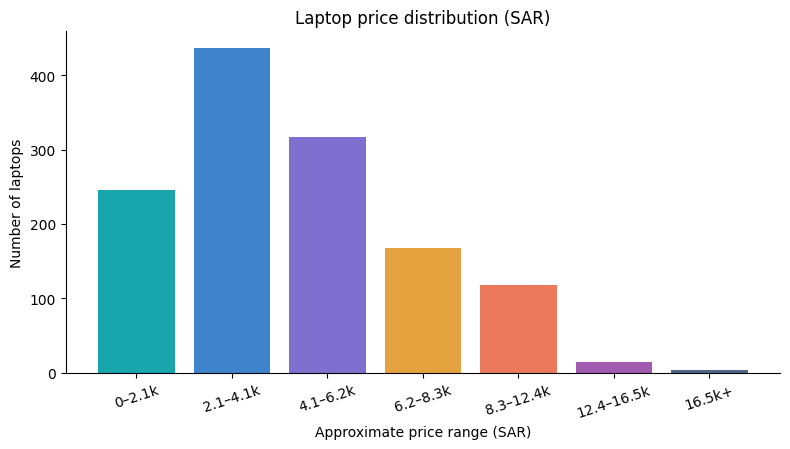

,number of laptops
Price_SAR,
0–2.1k,245
2.1–4.1k,437
4.1–6.2k,317
6.2–8.3k,167
8.3–12.4k,118
12.4–16.5k,15
16.5k+,4


In [11]:
# SAR equivalents of the original euro intervals
price_edges = [0, 500, 1000, 1500, 2000, 3000, 4000, float('inf')]
price_edges_sar = [x * EUR_TO_SAR for x in price_edges]
price_labels = ['0–2.1k', '2.1–4.1k', '4.1–6.2k', '6.2–8.3k', '8.3–12.4k', '12.4–16.5k', '16.5k+']
price_ranges = pd.cut(clean['Price_SAR'], bins=price_edges_sar, labels=price_labels, right=False)
price_counts = price_ranges.value_counts().reindex(price_labels, fill_value=0)
fig, ax = plt.subplots(figsize=(8, 4.6))
colors = ['#18A6AC', '#3F83CA', '#7F70CF', '#E4A33E', '#EC795C', '#A05AAE', '#4E6886']
ax.bar(price_counts.index, price_counts.values, color=colors)
ax.set_title('Laptop price distribution (SAR)')
ax.set_xlabel('Approximate price range (SAR)')
ax.set_ylabel('Number of laptops')
ax.tick_params(axis='x', rotation=18)
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig(figure_folder / '01_price_distribution.png', dpi=170)
plt.show()
display(price_counts.to_frame('number of laptops'))

### Step 15 — Create Visualization 2: Brand Comparison
The chart compares median prices in SAR among brands with at least 20 laptop listings. Smaller categories are excluded from the visual comparison to limit the influence of very small groups.


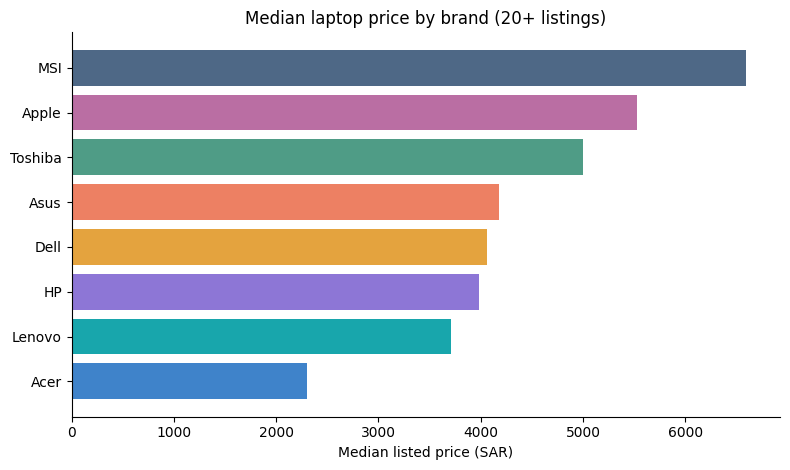

,Company,n_laptops,median_price
0,Acer,103,2306.21
10,Lenovo,297,3708.91
7,HP,274,3987.40
4,Dell,297,4063.72
2,Asus,158,4177.17
16,Toshiba,48,4998.16
1,Apple,21,5527.03
11,MSI,54,6596.83


In [12]:
brands_to_plot = brand_summary.loc[brand_summary['n_laptops'] >= 20].sort_values('median_price')
fig, ax = plt.subplots(figsize=(8, 4.8))
colors = ['#3F83CA', '#18A6AC', '#8D76D6', '#E4A33E', '#ED8063', '#4F9C86', '#BA6EA3', '#4E6886']
ax.barh(brands_to_plot['Company'], brands_to_plot['median_price'], color=colors[:len(brands_to_plot)])
ax.set_title('Median laptop price by brand (20+ listings)')
ax.set_xlabel('Median listed price (SAR)')
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig(figure_folder / '02_brand_median_prices.png', dpi=170)
plt.show()
display(brands_to_plot[['Company', 'n_laptops', 'median_price']].round(2))

### Step 16 — Create Visualization 3: RAM and Median Price
The chart compares median prices in SAR among RAM categories with at least 20 laptops. The plotted values represent group medians rather than prices of individual laptops.


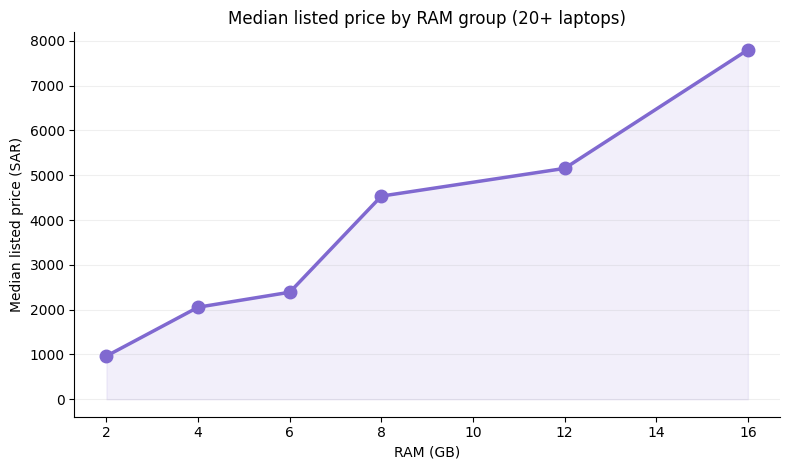

,RamGB,n_laptops,median_price
0,2,22,965.39
1,4,375,2054.55
2,6,41,2388.72
3,8,619,4534.03
4,12,25,5152.87
5,16,200,7799.44


In [13]:
ram_to_plot = ram_summary.loc[ram_summary['n_laptops'] >= 20].sort_values('RamGB')
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.plot(ram_to_plot['RamGB'], ram_to_plot['median_price'], marker='o', markersize=9,
        linewidth=2.5, color='#8069D0')
ax.fill_between(ram_to_plot['RamGB'].astype(float).to_numpy(),
                ram_to_plot['median_price'].astype(float).to_numpy(), color='#8069D0', alpha=.10)
ax.set_title('Median listed price by RAM group (20+ laptops)')
ax.set_xlabel('RAM (GB)')
ax.set_ylabel('Median listed price (SAR)')
ax.grid(axis='y', alpha=0.2)
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig(figure_folder / '03_ram_median_prices.png', dpi=170)
plt.show()
display(ram_to_plot[['RamGB', 'n_laptops', 'median_price']].round(2))

### Step 17 — Interpret the Visualizations
**Figure 1: Price ranges.** There are 998 laptops (76.6%) below the original €1,500 price cutoff, which is about **SAR 6,188** at the reference exchange rate. A smaller number of high-priced listings extends the price range to about SAR 25,162.

**Figure 2: Laptop brands.** The median listed price is about **SAR 6,597** for MSI (54 laptops) and **SAR 2,306** for Acer (103 laptops). Other specifications may also explain why the groups differ.

**Figure 3: RAM size.** Laptops with 4 GB RAM have a median price of about **SAR 2,055**, compared with about **SAR 7,799** for laptops with 16 GB RAM. The chart shows an association in these listings, not a causal effect.

In [14]:
# Numeric results used in the written interpretations
print(f'Mean: SAR {price_mean:,.2f} | Median: SAR {price_median:,.2f}')
if {'MSI', 'Acer'}.issubset(set(brands_to_plot['Company'])):
    display(brands_to_plot.loc[brands_to_plot['Company'].isin(['MSI', 'Acer']),
                                ['Company', 'n_laptops', 'median_price']].round(2))
if {4.0, 16.0}.issubset(set(ram_to_plot['RamGB'])):
    display(ram_to_plot.loc[ram_to_plot['RamGB'].isin([4.0, 16.0]),
                             ['RamGB', 'n_laptops', 'median_price']].round(2))

Mean: SAR 4,635.88 | Median: SAR 4,030.71


,Company,n_laptops,median_price
0,Acer,103,2306.21
11,MSI,54,6596.83


,RamGB,n_laptops,median_price
1,4,375,2054.55
5,16,200,7799.44


### Step 18 — Results and Conclusion
The laptop prices range from about **SAR 718 to SAR 25,162**. The median is about **SAR 4,031** and the mean is about **SAR 4,636**. A few expensive models make the mean higher than the median.

Typical prices also differ by brand and RAM group. The correlation between RAM capacity and listed price is positive (approximately **0.743**), although other specifications may explain some of that relationship.

**Limitations:** The dataset does not identify a clear collection period, and the exchange-rate conversion does not turn these into current Saudi retail prices. The results describe this dataset only.

### Step 19 — Jupyter Notebook
The notebook contains the Python code, data checks, tables, charts, and discussion in the same order as the analysis.

### Step 20 — README.md
The README records the dataset source, the SAR exchange-rate reference, the research question, the analysis steps, and instructions for running the notebook.

### Step 21 — GitHub Repository
**Repository name:** `Group3-Laptop-Price-Analysis`

Project folders: `notebooks/`, `data/`, `outputs/figures/`, and `presentation/`. The README is kept at the top level.

### Step 22 — Project Files on GitHub
The project files to publish are the Jupyter notebook, README, source information, three chart images, and presentation. The original dataset is downloaded from its public source when the notebook runs.

### Step 23 — Verify Project Outputs
The following check confirms that the cleaned data and three figures have been saved.

In [15]:
expected_figures = [
    '01_price_distribution.png',
    '02_brand_median_prices.png',
    '03_ram_median_prices.png'
]
assert clean_file.exists(), 'Cleaned CSV was not saved.'
assert all((figure_folder / name).exists() for name in expected_figures), 'A chart file is missing.'
print('Cleaned data and charts are ready.')
print('Data rows:', len(clean))
print('Figures:', ', '.join(expected_figures))

Cleaned data and charts are ready.
Data rows: 1303
Figures: 01_price_distribution.png, 02_brand_median_prices.png, 03_ram_median_prices.png


### Step 24 — PowerPoint Presentation
The slides summarize the question, dataset, cleaning and transformation steps, three charts, findings, limitations, and course skills.

**Presentation:** `presentation/Group3_Laptop_Price_Analysis.pptx`

---
**References:** 2323 CIS Lab Manual, LAB 14–15 (pp. 31–33); MainakRepositor, `laptop_price.csv` (accessed 24 November 2026); X-Rates, historical EUR/SAR reference for 23 November 2026 (1 EUR ≈ 4.1256 SAR).